![](../assets/spun_logo.png)


# SPUN Quickstart: Inference & Mosaicking 🏔️🛰️

This notebook demonstrates how to run the SPUN (Snow Patch U-Net) model on custom regions of interest. 

We will cover two approaches to handling Earth Engine data:
1. **Raw Tile Retrieval:** Fetching every single satellite pass over an area.
2. **Cloud-Optimized Mosaics:** Combining overlapping passes to look "through" moving clouds and retrieve the maximum amount of clear-sky snow data per day.

<div class="alert alert-block alert-warning">
    <b>Note: </b>This tutorial can run on CPU or GPU but will be much MUCH faster on GPU.
</div>

<a href="https://colab.research.google.com/github/leamhowe/spun/tree/main/example_notebooks/01_quickstart_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Download SPUN

In [ ]:
import os
import urllib.request
from src.config import DEFAULT_MODEL_WEIGHTS

ZENODO_URL = "https://zenodo.org/record/YOUR_ID/files/spun_final_model.pt"

# If the model isn't there, download it automatically!
if not DEFAULT_MODEL_WEIGHTS.exists():
    print("Downloading pre-trained model from Zenodo (125MB). This only happens once...")
    urllib.request.urlretrieve(ZENODO_URL, DEFAULT_MODEL_WEIGHTS)
    print("Download complete!")

# Now load the model normally

## Setup & Config

In [10]:
import sys
# Aggressively remove the rogue ~/.local folder from Python's search path (JASMIN HPC fix)
sys.path = [p for p in sys.path if '.local' not in p]

import os
import json
import torch
import ee

# Add repository root to the path
repo_root = os.path.abspath('..')
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Import our custom utilities
from src.utils.gee_utils import authenticate_ee, get_individual_s2_tiles, get_daily_cloud_optimized_mosaics
from src.utils.inference_utils import instantiate_model, predict_batched

# Authenticate with Earth Engine
CREDENTIALS_PATH = '/home/users/leamhowe/ee-credentials/ee-snow-patches-81eaf6e60bf9.json'
authenticate_ee(CREDENTIALS_PATH)

# --- USER CONFIGURATION ---
GEOJSON_PATH = 'cairngorm.geojson' 
START_DATE = '2026-04-25'
END_DATE = '2026-05-10' 
MODEL_WEIGHTS = '../SPUN.pt'

# Set maximum allowed cloud cover percentage for the ROI (0-100)
# Setting this to 60.0 means it will skip any images that are more than 60% cloudy. We keep it at 100% for this example to show SPUN can handle cloud.
MAX_CLOUD_COVER = 100.0 

# Set clear threshold against which the CloudScore+ cs_cdf product is thresholded to mask cloud. Standard that was used in training SPUN was 0.5. But you can increase this if you want to mask cloud more strictly. 
# See https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_CLOUD_SCORE_PLUS_V1_S2_HARMONIZED for more details.
# there is an interactive app to explore the threshold here: https://earthengine-ai.projects.earthengine.app/view/cloud-score-plus-collection-explorer
CLEAR_THRESHOLD = 0.50 

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12'] # bands required by SPUN
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Earth Engine Initialised Successfully!
Using device: cuda


## Setup Visualization
Before we fetch the data, let's define a reusable plotting function. This keeps our inference loops clean while allowing us to easily tweak the visual output (colormaps, thresholds, etc.).

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

def plot_snow_maps(title_text, img_array, prediction_np):
    """Generates a 1x3 plot showing RGB, Continuous SCF, and Binary Snow Mask."""
    # Extract RGB (Bands 4, 3, 2 which are indices 3, 2, 1)
    rgb = np.stack([img_array[:, :, 3], img_array[:, :, 2], img_array[:, :, 1]], axis=-1)
    rgb_bright = np.power(np.clip(rgb, 0, 1), 0.65) # Gamma correction
    
    is_cloud = (prediction_np == 200)
    scf_masked = np.ma.masked_where(is_cloud, prediction_np)
    
    binary_map = np.zeros_like(prediction_np, dtype=np.int8)
    binary_map[(~is_cloud) & (prediction_np > 50.0)] = 1
    binary_map[is_cloud] = 2

    # --- Plotting ---
    cmap_scf = plt.get_cmap('viridis')
    cmap_scf.set_bad(color='red')
    cmap_bin = mcolors.ListedColormap(['black', 'cyan', 'red'])
    norm_bin = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_bin.N)

    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(title_text, fontsize=14, fontweight='bold')

    axs[0].imshow(rgb_bright)
    axs[0].set_title('Sentinel-2 RGB', fontsize=12)
    axs[0].axis('off')

    im2 = axs[1].imshow(scf_masked, cmap=cmap_scf, vmin=0, vmax=100)
    axs[1].set_title('SPUN Predicted SCF', fontsize=12)
    axs[1].axis('off')
    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, label='Snow Fraction (%)')

    axs[2].imshow(binary_map, cmap=cmap_bin, norm=norm_bin, interpolation='nearest')
    axs[2].set_title('Binary Snow Mask', fontsize=12)
    axs[2].axis('off')

    patches = [
        mpatches.Patch(color='black', label='Ground'),
        mpatches.Patch(color='cyan', label='Snow'),
        mpatches.Patch(color='red', label='Cloud / No Data')
    ]
    axs[2].legend(handles=patches, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

## Part 1: Predicting on Raw Satellite Passes

Sentinel-2 data is divided into 100km × 100km "MGRS Tiles". When your Region of Interest (ROI) crosses a tile boundary, or when overlapping satellite orbits occur, you will often find multiple images taken on the *exact same day*, just seconds or minutes apart.

First, let's fetch every individual raw tile to see what the model does with these fragmented, cloudy passes.

In [13]:
# 1. Load GeoJSON to Earth Engine Geometry
with open(GEOJSON_PATH, 'r') as f:
    coords = json.load(f)['features'][0]['geometry']['coordinates']
roi = ee.Geometry.Polygon(coords)

# 2. Fetch Raw Tiles
print("Fetching raw, individual Sentinel-2 tiles...")
raw_images = get_individual_s2_tiles(roi, START_DATE, END_DATE, BANDS, max_cloud_cover=MAX_CLOUD_COVER, clear_threshold=CLEAR_THRESHOLD)

Fetching raw, individual Sentinel-2 tiles...
Found 9 individual optical tile(s). Evaluating cloud cover...
Analyzing Tile 1/9 from 2026-04-26 11:35:21...
  -> ROI is 16.8% cloudy. Downloading 13-band optical data...
Analyzing Tile 2/9 from 2026-04-26 11:45:38...
  -> ROI is 23.7% cloudy. Downloading 13-band optical data...
Analyzing Tile 3/9 from 2026-04-29 11:45:18...
  -> ROI is 1.8% cloudy. Downloading 13-band optical data...
Analyzing Tile 4/9 from 2026-05-01 11:35:26...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 5/9 from 2026-05-03 11:35:39...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 6/9 from 2026-05-04 11:45:22...
  -> ROI is 42.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 7/9 from 2026-05-06 11:35:22...
  -> ROI is 99.3% cloudy. Downloading 13-band optical data...
Analyzing Tile 8/9 from 2026-05-06 11:45:34...
  -> ROI is 100.0% cloudy. Downloading 13-band optical data...
Analyzing Tile 9/9 


Loading SPUN Model...

--- Running Inference on Raw Tiles ---

Predicting on: 2026-04-26 11:35:21


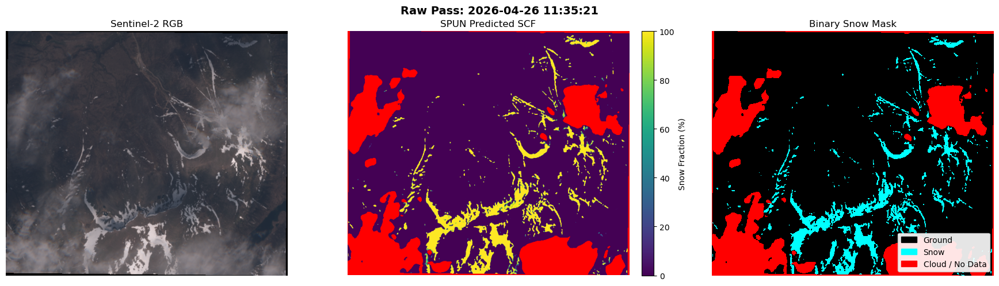


Predicting on: 2026-04-26 11:45:38


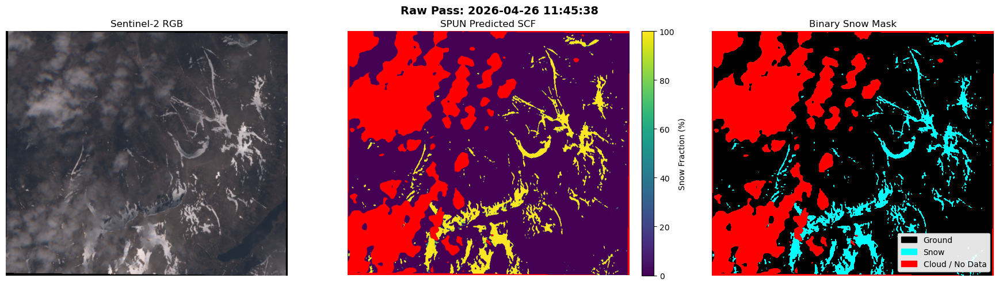


Predicting on: 2026-04-29 11:45:18


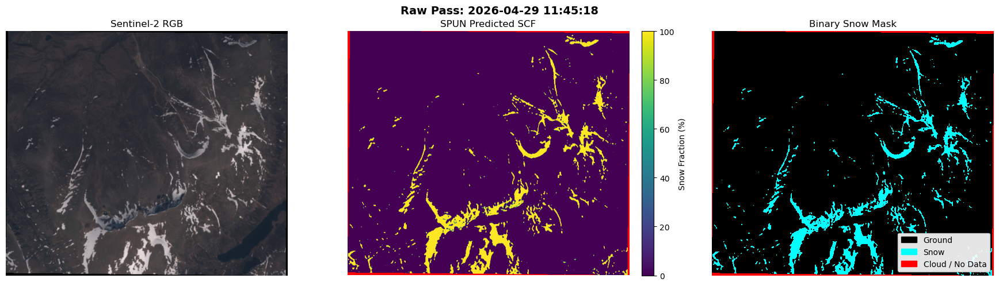


Predicting on: 2026-05-01 11:35:26


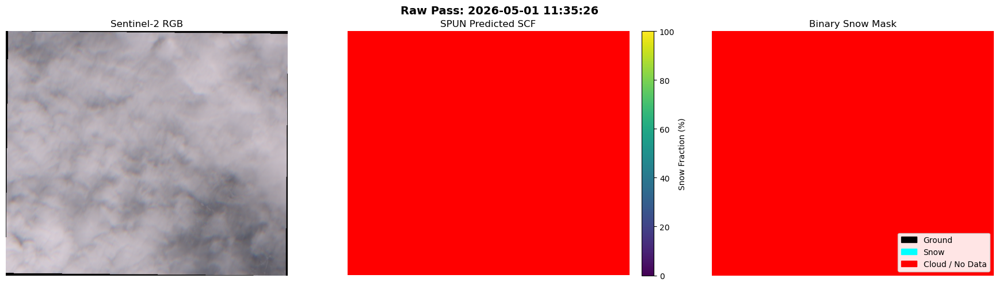


Predicting on: 2026-05-03 11:35:39


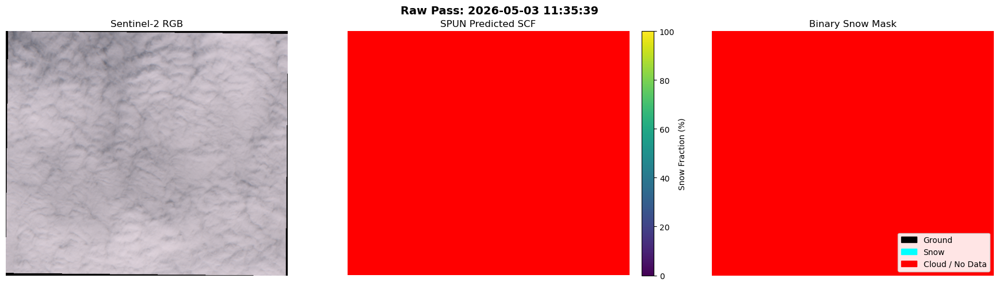


Predicting on: 2026-05-04 11:45:22


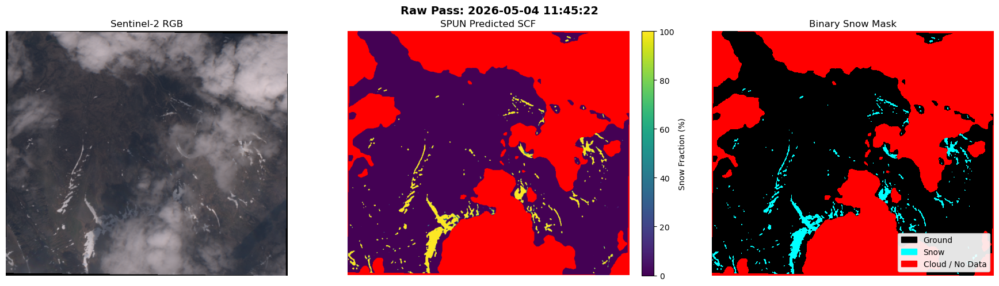


Predicting on: 2026-05-06 11:35:22


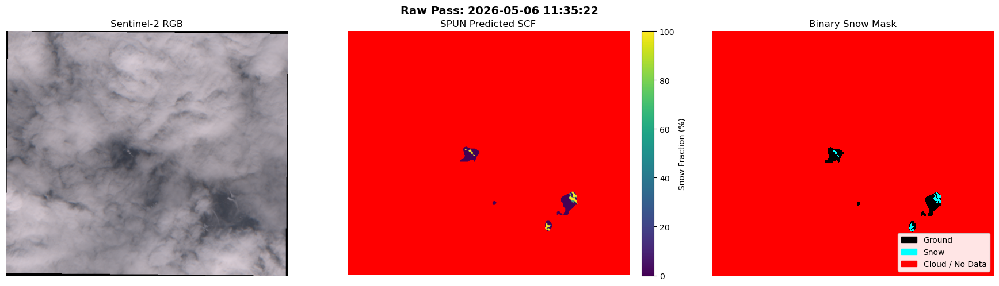


Predicting on: 2026-05-06 11:45:34


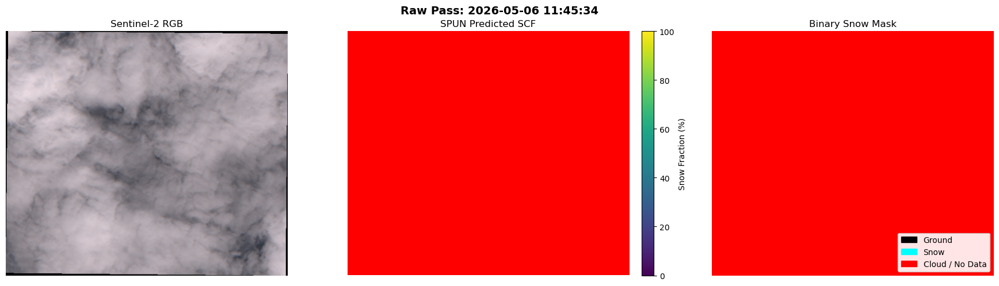


Predicting on: 2026-05-09 11:45:18


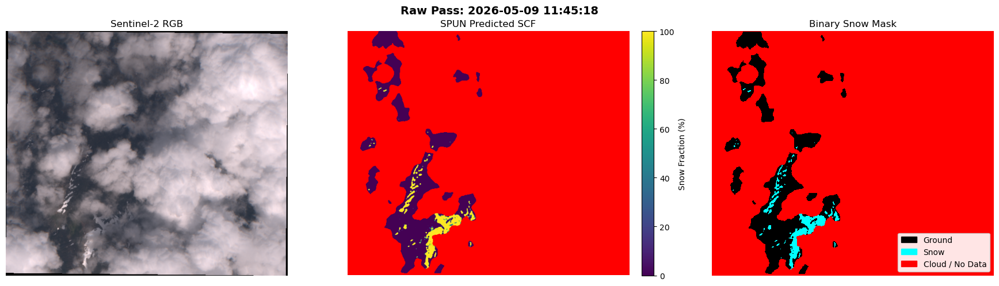

In [14]:
# 3. Load Model
print("\nLoading SPUN Model...")
model = instantiate_model(MODEL_WEIGHTS, BANDS, backbone='resnet50', device=device)

# 4. Predict
print("\n--- Running Inference on Raw Tiles ---")
for item in raw_images:
    if item['optical'] is None: continue
        
    print(f"\nPredicting on: {item['date']}")
    prediction_np = predict_batched(
        model=model, image_array=item['optical'], device=device, 
        batch_size=16, num_workers=0, cloud_mask_array=item['cloud_mask']
    )
    
    plot_snow_maps(f"Raw Pass: {item['date']}", item['optical'], prediction_np)

## Part 2: The Cloud-Optimized Mosaic

Looking at individual passes is great, but as you can see above, clouds often obscure the snow, and overlapping tile boundaries can cut our ROI in half. 

Because clouds move, different satellite passes on the same day might have clear views of *different parts of the mountain*. We can use Google Earth Engine's `qualityMosaic` function to dynamically drill down through all overlapping images on a given day, selecting only the pixels with the highest clear-sky probability (`cs_cdf`).

This yields a single, seamless, "best possible" snow map for each day.

In [16]:
# 1. Fetch Cloud-Optimized Daily Mosaics
print("Building and fetching Cloud-Optimized Daily Mosaics...")
optimized_images = get_daily_cloud_optimized_mosaics(roi, START_DATE, END_DATE, BANDS, max_cloud_cover=MAX_CLOUD_COVER, clear_threshold=CLEAR_THRESHOLD)

Building and fetching Cloud-Optimized Daily Mosaics...
Found 9 raw tiles grouped into 7 unique day(s).
Analyzing daily composite for: 2026-04-26...
  -> Composite is 6.3% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-04-29...
  -> Composite is 0.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-01...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-03...
  -> Composite is 100.0% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-04...
  -> Composite is 41.2% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-06...
  -> Composite is 99.3% cloudy. Downloading 13-band optical data...
Analyzing daily composite for: 2026-05-09...
  -> Composite is 90.8% cloudy. Downloading 13-band optical data...



--- Running Inference on Optimized Mosaics ---

Predicting on Daily Composite: 2026-04-26


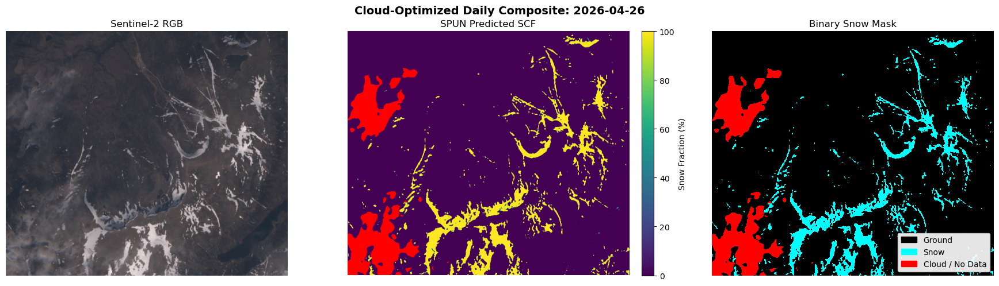


Predicting on Daily Composite: 2026-04-29


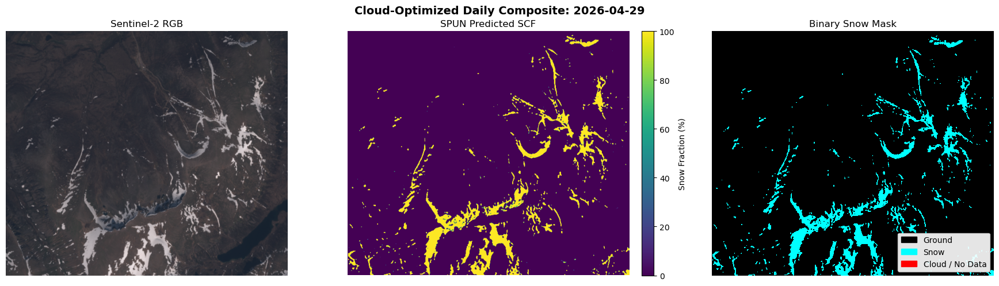


Predicting on Daily Composite: 2026-05-01


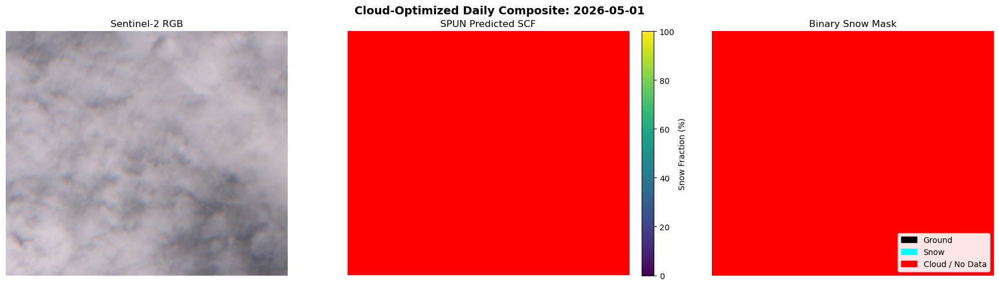


Predicting on Daily Composite: 2026-05-03


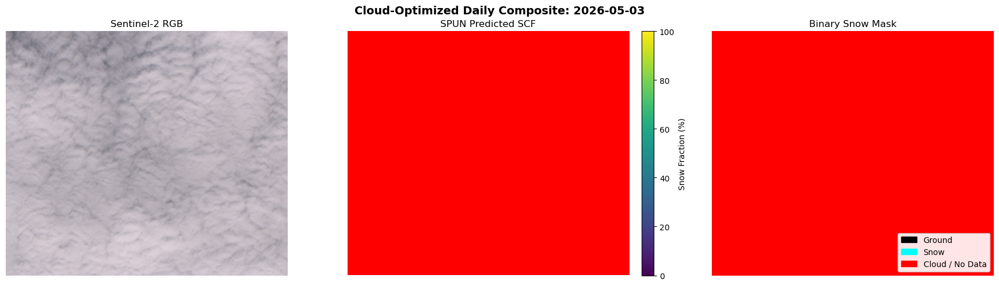


Predicting on Daily Composite: 2026-05-04


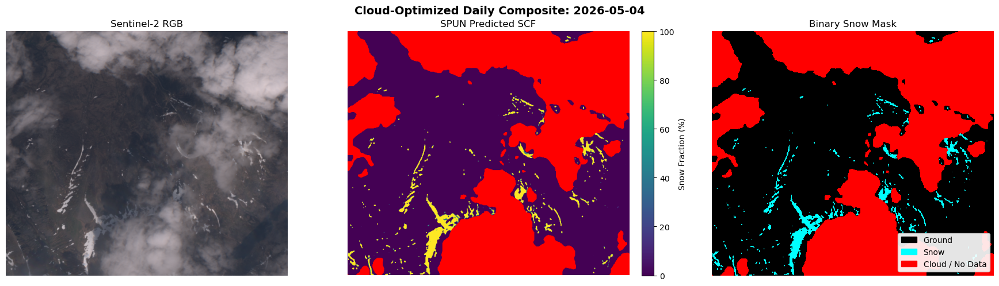


Predicting on Daily Composite: 2026-05-06


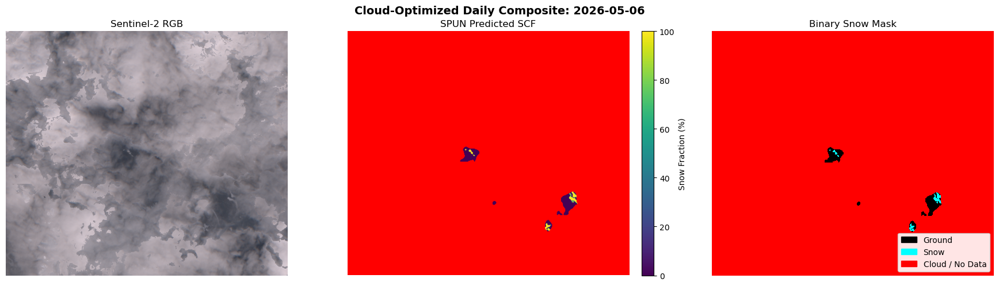


Predicting on Daily Composite: 2026-05-09


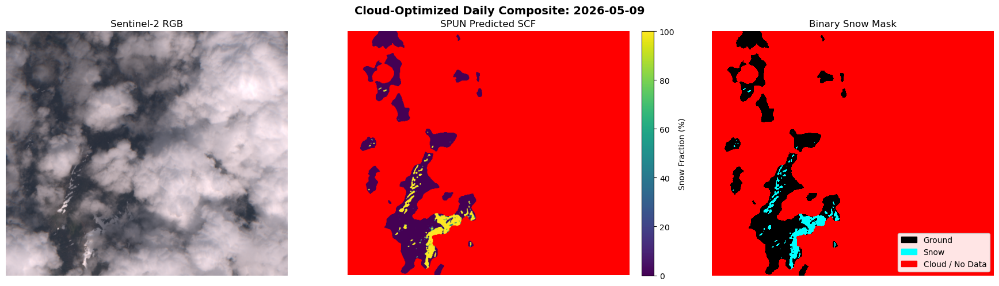

In [17]:
# 2. Predict
print("\n--- Running Inference on Optimized Mosaics ---")
for item in optimized_images:
    if item['optical'] is None: continue
        
    print(f"\nPredicting on Daily Composite: {item['date']}")
    prediction_np = predict_batched(
        model=model, image_array=item['optical'], device=device, 
        batch_size=16, num_workers=0, cloud_mask_array=item['cloud_mask']
    )
    
    plot_snow_maps(f"Cloud-Optimized Daily Composite: {item['date']}", item['optical'], prediction_np)

# Australia

In [29]:
# --- USER CONFIGURATION ---
# GEOJSON_PATH = 'ben_lomond.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'cairngorm.geojson' # Path to your geojson.io file
GEOJSON_PATH = 'australia_mount_twynam.geojson' # Path to your geojson.io file
START_DATE = '2025-12-04'
END_DATE = '2025-12-15' # Will search for a clear image in this window
MODEL_WEIGHTS = '../SPUN.pt'

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [30]:
import json
import numpy as np
import ee
from geemap import ee_to_numpy

# 1. Load GeoJSON and convert to Earth Engine Geometry
with open(GEOJSON_PATH, 'r') as f:
    roi_data = json.load(f)

coords = roi_data['features'][0]['geometry']['coordinates']
roi = ee.Geometry.Polygon(coords)

# 2. Base Earth Engine query
print(f"Querying Earth Engine between {START_DATE} and {END_DATE}...")
s2_col = ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)
qa_col = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)

# --- THE FIX: Link the collections so every S2 image has a 'cs_cdf' band built-in ---
linked_col = s2_col.linkCollection(qa_col, ['cs_cdf'])

count = linked_col.size().getInfo()

if count == 0:
    print("No images found in this date range.")
    image_list = []
else:
    # 3. Ask Earth Engine for a list of UNIQUE days
    def get_date(img):
        return ee.Image(img).date().format('YYYY-MM-dd')
    
    unique_dates = linked_col.toList(count).map(get_date).distinct().getInfo()
    print(f"Found {count} raw tiles grouped into {len(unique_dates)} unique day(s).")
    
    image_list = []
    
    # 4. Loop through each unique day, optimize for clear pixels, and download
    for date_str in unique_dates:
        print(f"Building cloud-optimized mosaic for: {date_str}...")
        
        day_start = ee.Date(date_str)
        day_end = day_start.advance(1, 'day')
        
        daily_col = linked_col.filterDate(day_start, day_end)
        
        # --- THE FIX: Pick the pixels with the highest clear-sky probability! ---
        best_pixel_mosaic = daily_col.qualityMosaic('cs_cdf')
        
        # Get the projection from the first image of the day
        ref_proj = daily_col.first().select('B2').projection()
        
        # Reproject and Clip the optimized composite
        final_img = best_pixel_mosaic.reproject(ref_proj).clip(roi)
        
        # Download Optical Bands
        img_np = ee_to_numpy(final_img.select(BANDS), region=roi, scale=10)
        if img_np is not None:
            img_np = np.clip(img_np / 10000.0, 0.0, None)
            
        # Download the CloudScore+ mask from the composite
        qa_np = ee_to_numpy(final_img.select('cs_cdf'), region=roi, scale=10)
            
        image_list.append({
            'date': date_str,
            'optical': img_np,
            'cloud_mask': qa_np
        })
        
print("All daily downloads complete!")

Querying Earth Engine between 2025-12-04 and 2025-12-15...
Found 6 raw tiles grouped into 6 unique day(s).
Building cloud-optimized mosaic for: 2025-12-04...
Building cloud-optimized mosaic for: 2025-12-07...
Building cloud-optimized mosaic for: 2025-12-09...
Building cloud-optimized mosaic for: 2025-12-11...
Building cloud-optimized mosaic for: 2025-12-12...
Building cloud-optimized mosaic for: 2025-12-14...
All daily downloads complete!


Loading SPUN...
Instantiating model with 13 input channels.
Model loaded successfully.
Starting Inference and Plotting...

Predicting on: 2025-12-04
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 0


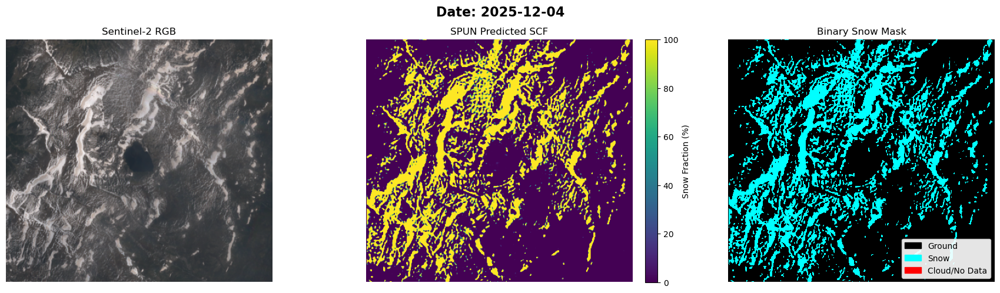


Predicting on: 2025-12-07
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 0


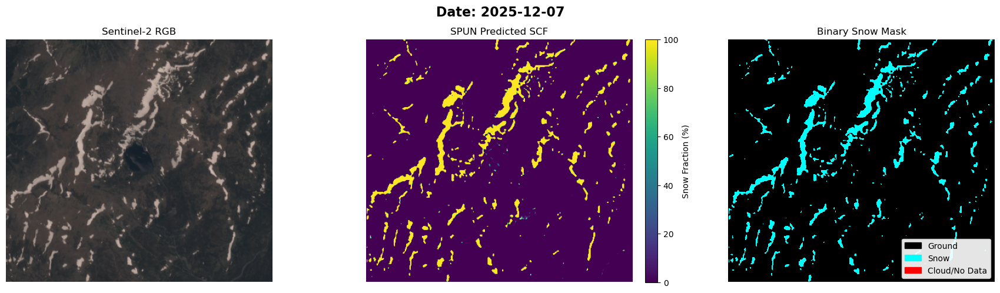


Predicting on: 2025-12-09
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 29221


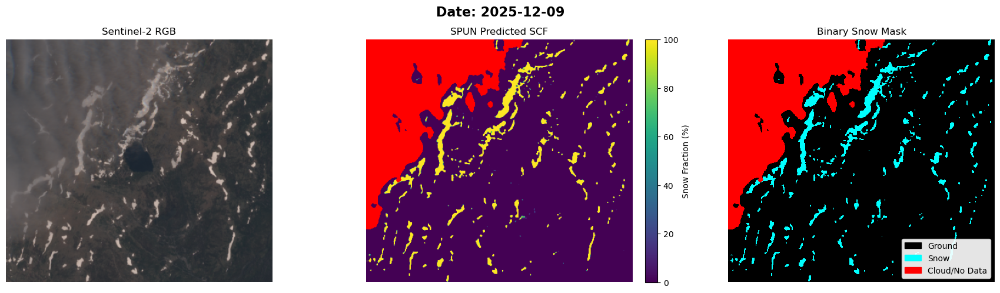


Predicting on: 2025-12-11
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 135480


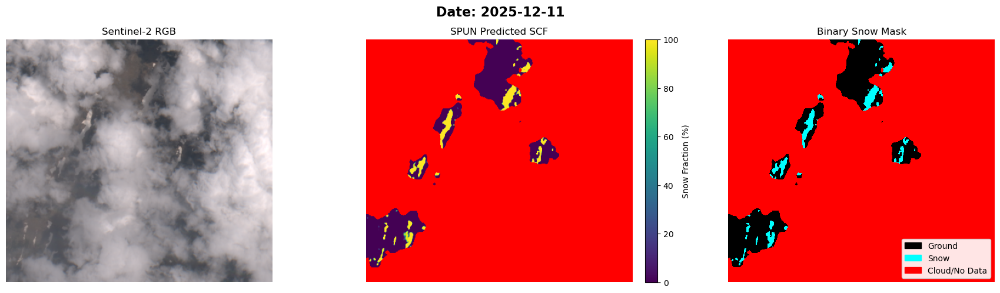


Predicting on: 2025-12-12
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 150192


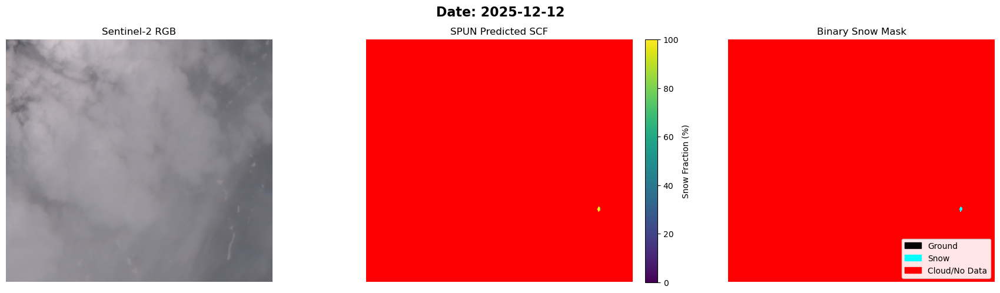


Predicting on: 2025-12-14
Using numpy array of shape (13, 370, 406) for prediction.
Starting batched GPU inference on 30 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 150220


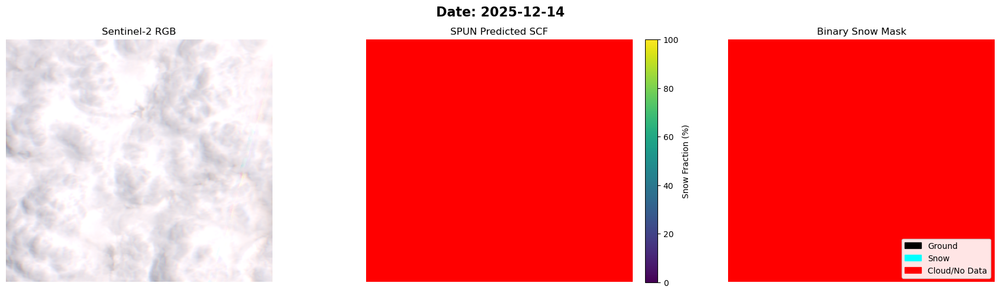

In [31]:
import matplotlib.patches as mpatches

# Load the SPUN Model
print("Loading SPUN...")
model = instantiate_model(
    model_path=MODEL_WEIGHTS, 
    bands=BANDS, 
    backbone='resnet50', 
    device=device
)

# Setup colormaps
cmap_scf = plt.get_cmap('viridis')
cmap_scf.set_bad(color='red')
cmap_bin = mcolors.ListedColormap(['black', 'cyan', 'red'])
norm_bin = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_bin.N)

print("Starting Inference and Plotting...")

for item in image_list:
    date_str = item['date']
    img_array = item['optical']
    qa_array = item['cloud_mask']
    
    if img_array is None:
        continue
        
    print(f"\nPredicting on: {date_str}")
    
    # Run Inference
    prediction_np = predict_batched(
        model=model, 
        image_array=img_array, 
        device=device, 
        batch_size=16, 
        num_workers=0, 
        cloud_mask_array=qa_array
    )
    
    # --- Prepare Visuals ---
    rgb = np.stack([img_array[:, :, 3], img_array[:, :, 2], img_array[:, :, 1]], axis=-1)
    rgb_bright = np.power(np.clip(rgb, 0, 1), 0.65)
    
    is_cloud = (prediction_np == 200)
    scf_masked = np.ma.masked_where(is_cloud, prediction_np)
    
    binary_map = np.zeros_like(prediction_np, dtype=np.int8)
    binary_map[(~is_cloud) & (prediction_np > 50.0)] = 1
    binary_map[is_cloud] = 2

    # --- Plotting ---
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Date: {date_str}", fontsize=16, fontweight='bold')

    # 1. RGB
    axs[0].imshow(rgb_bright)
    axs[0].set_title('Sentinel-2 RGB', fontsize=12)
    axs[0].axis('off')

    # 2. Continuous SCF
    im2 = axs[1].imshow(scf_masked, cmap=cmap_scf, vmin=0, vmax=100)
    axs[1].set_title('SPUN Predicted SCF', fontsize=12)
    axs[1].axis('off')
    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, label='Snow Fraction (%)')

    # 3. Binary Classification
    axs[2].imshow(binary_map, cmap=cmap_bin, norm=norm_bin, interpolation='nearest')
    axs[2].set_title('Binary Snow Mask', fontsize=12)
    axs[2].axis('off')

    patches = [
        mpatches.Patch(color='black', label='Ground'),
        mpatches.Patch(color='cyan', label='Snow'),
        mpatches.Patch(color='red', label='Cloud/No Data')
    ]
    axs[2].legend(handles=patches, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

In [19]:
# --- USER CONFIGURATION ---
# GEOJSON_PATH = 'ben_lomond.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'cairngorm.geojson' # Path to your geojson.io file
GEOJSON_PATH = 'australia_mount_twynam.geojson' # Path to your geojson.io file
START_DATE = '2025-11-25'
END_DATE = '2025-12-05' # Will search for a clear image in this window
MODEL_WEIGHTS = '../SPUN.pt'

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [20]:
# --- USER CONFIGURATION ---
# GEOJSON_PATH = 'ben_lomond.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'cairngorm.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'australia_mount_twynam.geojson' # Path to your geojson.io file
GEOJSON_PATH = 'australia_etheridge.geojson' # Path to your geojson.io file
START_DATE = '2025-11-25'
END_DATE = '2025-12-15' # Will search for a clear image in this window
MODEL_WEIGHTS = '../SPUN.pt'

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [21]:
import datetime
from geemap import ee_to_numpy

# 1. Load GeoJSON and convert to Earth Engine Geometry
with open(GEOJSON_PATH, 'r') as f:
    roi_data = json.load(f)

coords = roi_data['features'][0]['geometry']['coordinates']
roi = ee.Geometry.Polygon(coords)

# 2. Custom function to fetch individual images instead of a mosaic
print(f"Querying Earth Engine between {START_DATE} and {END_DATE}...")
s2_col = ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)
qa_col = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)

count = s2_col.size().getInfo()
print(f"Found {count} individual optical tile(s). Downloading...")

image_list = []
if count > 0:
    s2_list = s2_col.toList(count)
    
    for i in range(count):
        # Get individual image and its timestamp
        img = ee.Image(s2_list.get(i))
        date_msec = img.get('system:time_start').getInfo()
        date_str = datetime.datetime.fromtimestamp(date_msec/1000.0).strftime('%Y-%m-%d %H:%M')
        
        print(f"Downloading Image {i+1}/{count} from {date_str}...")
        
        # Reproject and Clip
        ref_proj = img.select('B2').projection()
        img_clipped = img.select(BANDS).reproject(ref_proj).clip(roi)
        img_np = ee_to_numpy(img_clipped, region=roi, scale=10)
        
        # Standardize optical data immediately
        if img_np is not None:
            img_np = np.clip(img_np / 10000.0, 0.0, None)
        
        # Try to find matching CloudScore+ mask
        img_id = img.get('system:index').getInfo()
        qa_img = qa_col.filter(ee.Filter.eq('system:index', img_id)).first()
        
        qa_np = None
        if qa_img is not None:
            qa_clipped = ee.Image(qa_img).select('cs_cdf').reproject(ref_proj).clip(roi)
            qa_np = ee_to_numpy(qa_clipped, region=roi, scale=10)
            
        image_list.append({
            'date': date_str,
            'optical': img_np,
            'cloud_mask': qa_np
        })

print("All downloads complete!")

Querying Earth Engine between 2025-11-25 and 2025-12-15...
Found 10 individual optical tile(s). Downloading...
All downloads complete!


Loading SPUN...
Instantiating model with 13 input channels.
Model loaded successfully.
Starting Inference and Plotting...

Predicting on: 2025-11-27 00:16
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 1396


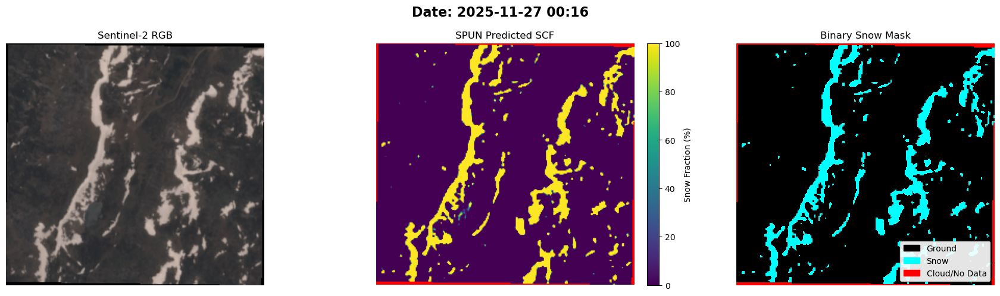


Predicting on: 2025-11-29 00:07
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 57784


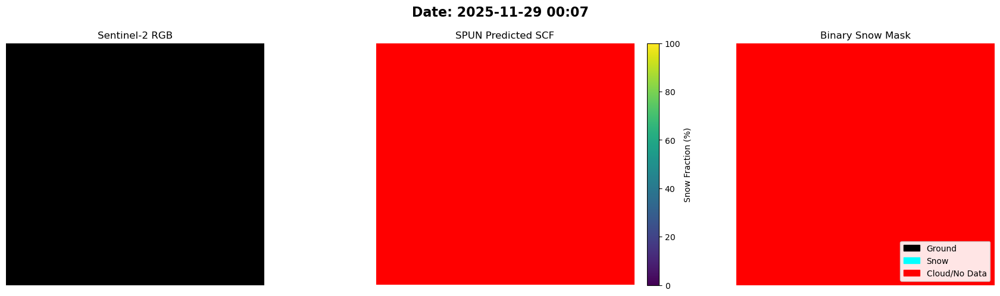


Predicting on: 2025-11-29 00:07
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 57784


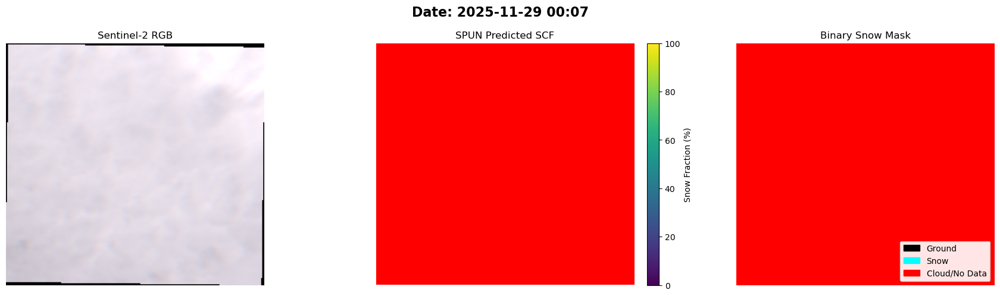


Predicting on: 2025-12-02 00:17
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 6688


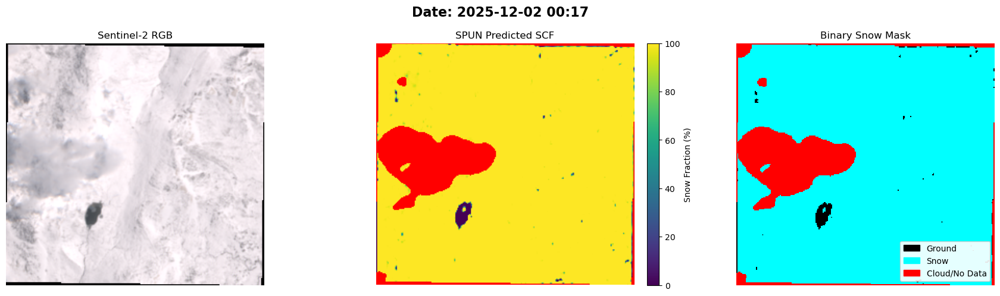


Predicting on: 2025-12-04 00:06
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 1396


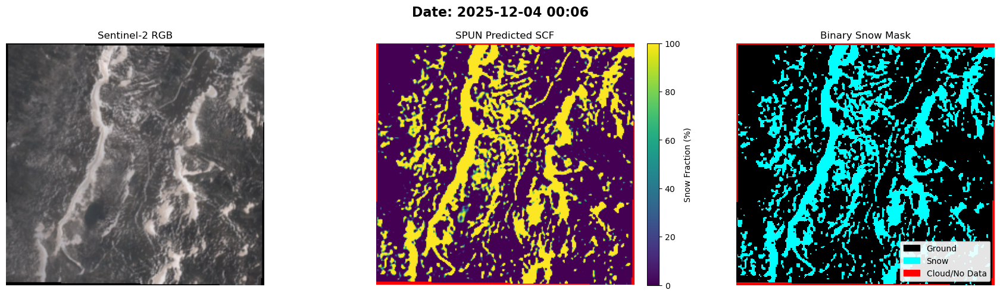


Predicting on: 2025-12-07 00:16
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 1396


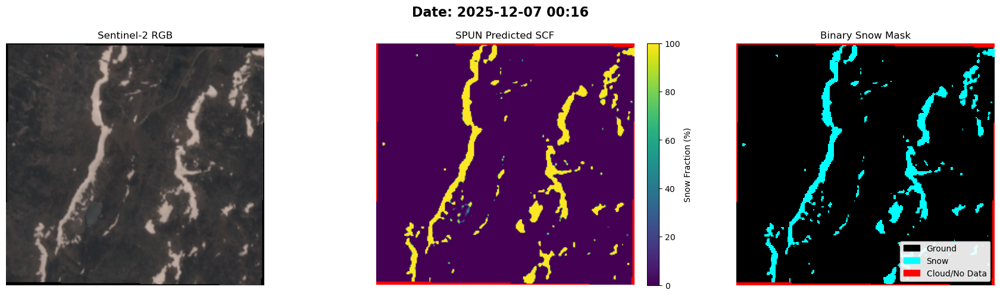


Predicting on: 2025-12-09 00:07
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 2945


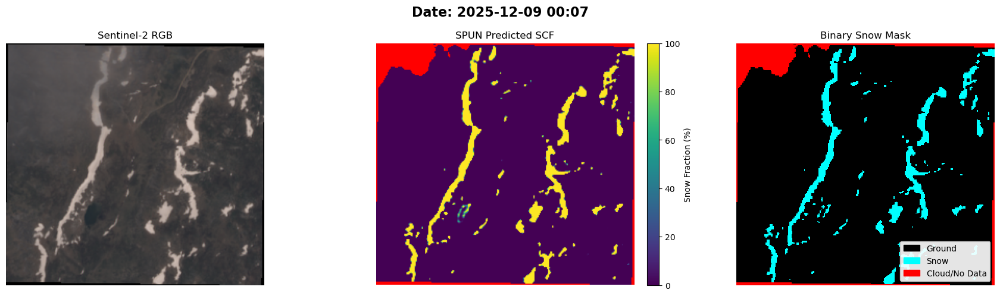


Predicting on: 2025-12-11 00:07
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 49706


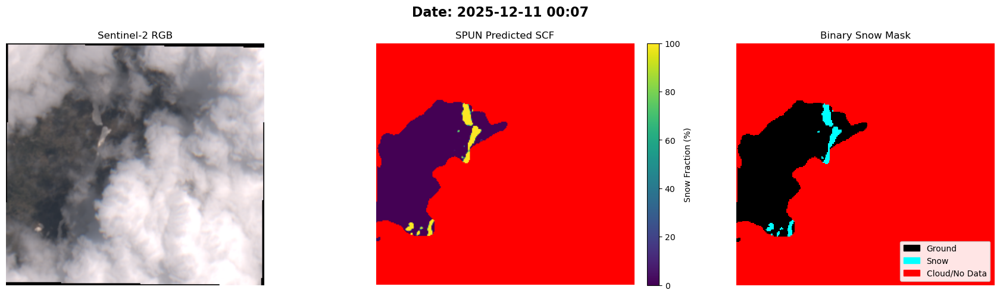


Predicting on: 2025-12-12 00:17
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 57784


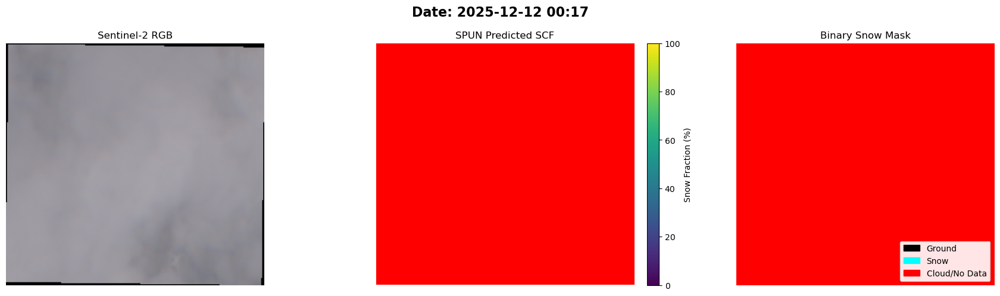


Predicting on: 2025-12-14 00:06
Using numpy array of shape (13, 233, 248) for prediction.
Starting batched GPU inference on 9 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 57784


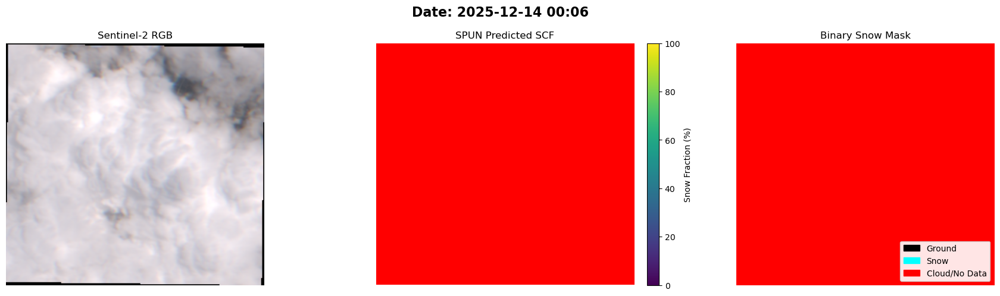

In [22]:
import matplotlib.patches as mpatches

# Load the SPUN Model
print("Loading SPUN...")
model = instantiate_model(
    model_path=MODEL_WEIGHTS, 
    bands=BANDS, 
    backbone='resnet50', 
    device=device
)

# Setup colormaps
cmap_scf = plt.get_cmap('viridis')
cmap_scf.set_bad(color='red')
cmap_bin = mcolors.ListedColormap(['black', 'cyan', 'red'])
norm_bin = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_bin.N)

print("Starting Inference and Plotting...")

for item in image_list:
    date_str = item['date']
    img_array = item['optical']
    qa_array = item['cloud_mask']
    
    if img_array is None:
        continue
        
    print(f"\nPredicting on: {date_str}")
    
    # Run Inference
    prediction_np = predict_batched(
        model=model, 
        image_array=img_array, 
        device=device, 
        batch_size=16, 
        num_workers=0, 
        cloud_mask_array=qa_array
    )
    
    # --- Prepare Visuals ---
    rgb = np.stack([img_array[:, :, 3], img_array[:, :, 2], img_array[:, :, 1]], axis=-1)
    rgb_bright = np.power(np.clip(rgb, 0, 1), 0.65)
    
    is_cloud = (prediction_np == 200)
    scf_masked = np.ma.masked_where(is_cloud, prediction_np)
    
    binary_map = np.zeros_like(prediction_np, dtype=np.int8)
    binary_map[(~is_cloud) & (prediction_np > 50.0)] = 1
    binary_map[is_cloud] = 2

    # --- Plotting ---
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Date: {date_str}", fontsize=16, fontweight='bold')

    # 1. RGB
    axs[0].imshow(rgb_bright)
    axs[0].set_title('Sentinel-2 RGB', fontsize=12)
    axs[0].axis('off')

    # 2. Continuous SCF
    im2 = axs[1].imshow(scf_masked, cmap=cmap_scf, vmin=0, vmax=100)
    axs[1].set_title('SPUN Predicted SCF', fontsize=12)
    axs[1].axis('off')
    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, label='Snow Fraction (%)')

    # 3. Binary Classification
    axs[2].imshow(binary_map, cmap=cmap_bin, norm=norm_bin, interpolation='nearest')
    axs[2].set_title('Binary Snow Mask', fontsize=12)
    axs[2].axis('off')

    patches = [
        mpatches.Patch(color='black', label='Ground'),
        mpatches.Patch(color='cyan', label='Snow'),
        mpatches.Patch(color='red', label='Cloud/No Data')
    ]
    axs[2].legend(handles=patches, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    plt.show()

## mount loch

In [26]:
# --- USER CONFIGURATION ---
# GEOJSON_PATH = 'ben_lomond.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'cairngorm.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'australia_mount_twynam.geojson' # Path to your geojson.io file
# GEOJSON_PATH = 'australia_etheridge.geojson' # Path to your geojson.io file
GEOJSON_PATH = 'australia_mount_loch.geojson' # Path to your geojson.io file
START_DATE = '2025-11-25'
END_DATE = '2025-12-10' # Will search for a clear image in this window
MODEL_WEIGHTS = '../SPUN.pt'

BANDS = ['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B10','B11','B12']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [27]:
import json
import numpy as np
import ee
from geemap import ee_to_numpy

# 1. Load GeoJSON and convert to Earth Engine Geometry
with open(GEOJSON_PATH, 'r') as f:
    roi_data = json.load(f)

coords = roi_data['features'][0]['geometry']['coordinates']
roi = ee.Geometry.Polygon(coords)

# 2. Base Earth Engine query
print(f"Querying Earth Engine between {START_DATE} and {END_DATE}...")
s2_col = ee.ImageCollection('COPERNICUS/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)
qa_col = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED').filterBounds(roi).filterDate(START_DATE, END_DATE)

# --- THE FIX: Link the collections so every S2 image has a 'cs_cdf' band built-in ---
linked_col = s2_col.linkCollection(qa_col, ['cs_cdf'])

count = linked_col.size().getInfo()

if count == 0:
    print("No images found in this date range.")
    image_list = []
else:
    # 3. Ask Earth Engine for a list of UNIQUE days
    def get_date(img):
        return ee.Image(img).date().format('YYYY-MM-dd')
    
    unique_dates = linked_col.toList(count).map(get_date).distinct().getInfo()
    print(f"Found {count} raw tiles grouped into {len(unique_dates)} unique day(s).")
    
    image_list = []
    
    # 4. Loop through each unique day, optimize for clear pixels, and download
    for date_str in unique_dates:
        print(f"Building cloud-optimized mosaic for: {date_str}...")
        
        day_start = ee.Date(date_str)
        day_end = day_start.advance(1, 'day')
        
        daily_col = linked_col.filterDate(day_start, day_end)
        
        # --- THE FIX: Pick the pixels with the highest clear-sky probability! ---
        best_pixel_mosaic = daily_col.qualityMosaic('cs_cdf')
        
        # Get the projection from the first image of the day
        ref_proj = daily_col.first().select('B2').projection()
        
        # Reproject and Clip the optimized composite
        final_img = best_pixel_mosaic.reproject(ref_proj).clip(roi)
        
        # Download Optical Bands
        img_np = ee_to_numpy(final_img.select(BANDS), region=roi, scale=10)
        if img_np is not None:
            img_np = np.clip(img_np / 10000.0, 0.0, None)
            
        # Download the CloudScore+ mask from the composite
        qa_np = ee_to_numpy(final_img.select('cs_cdf'), region=roi, scale=10)
            
        image_list.append({
            'date': date_str,
            'optical': img_np,
            'cloud_mask': qa_np
        })
        
print("All daily downloads complete!")

Querying Earth Engine between 2025-11-25 and 2025-12-10...
Found 3 raw tiles grouped into 3 unique day(s).
Building cloud-optimized mosaic for: 2025-11-27...
Building cloud-optimized mosaic for: 2025-12-02...
Building cloud-optimized mosaic for: 2025-12-07...
All daily downloads complete!


Loading SPUN...
Instantiating model with 13 input channels.
Model loaded successfully.
Starting Inference and Plotting...

Predicting on: 2025-11-27
Using numpy array of shape (13, 347, 341) for prediction.
Starting batched GPU inference on 25 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 117073


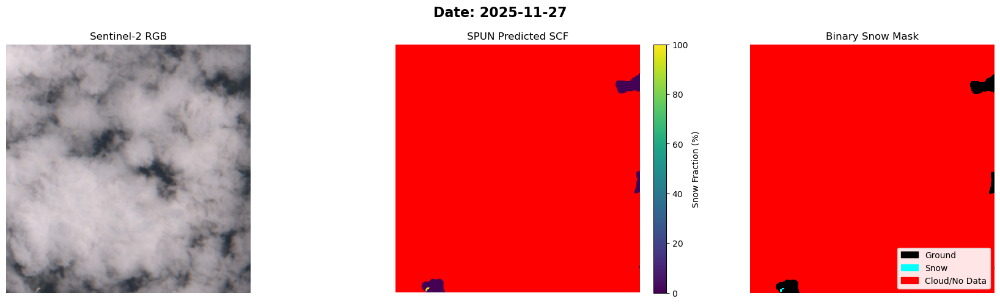


Predicting on: 2025-12-02
Using numpy array of shape (13, 347, 341) for prediction.
Starting batched GPU inference on 25 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 58734


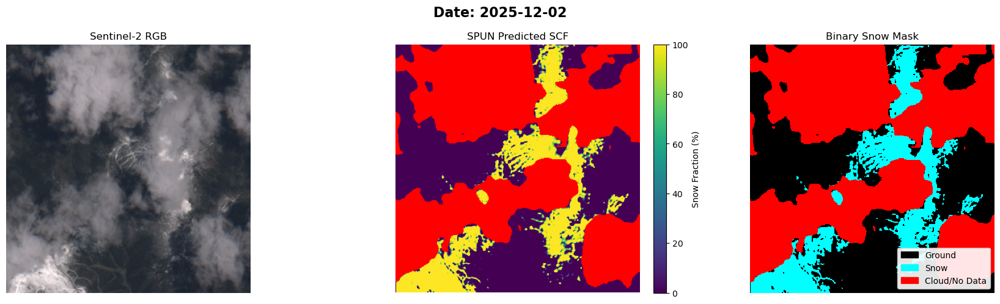


Predicting on: 2025-12-07
Using numpy array of shape (13, 347, 341) for prediction.
Starting batched GPU inference on 25 patches...
Batched inference complete.
Accumulating results...

Inference and blending complete.
Applying cloud mask...
Cloud mask applied. Pixels masked: 0


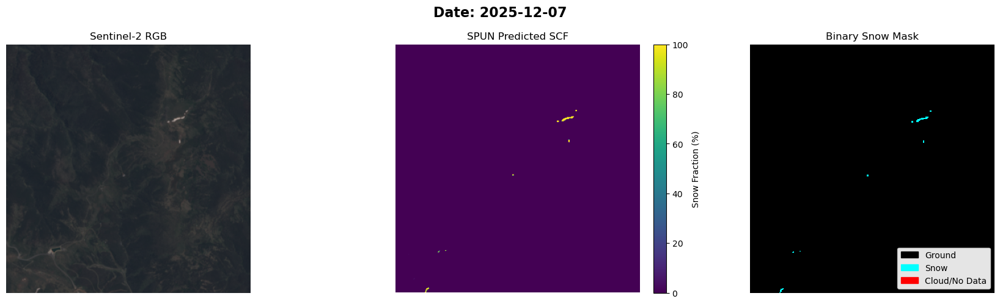

In [28]:
import matplotlib.patches as mpatches

# Load the SPUN Model
print("Loading SPUN...")
model = instantiate_model(
    model_path=MODEL_WEIGHTS, 
    bands=BANDS, 
    backbone='resnet50', 
    device=device
)

# Setup colormaps
cmap_scf = plt.get_cmap('viridis')
cmap_scf.set_bad(color='red')
cmap_bin = mcolors.ListedColormap(['black', 'cyan', 'red'])
norm_bin = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_bin.N)

print("Starting Inference and Plotting...")

for item in image_list:
    date_str = item['date']
    img_array = item['optical']
    qa_array = item['cloud_mask']
    
    if img_array is None:
        continue
        
    print(f"\nPredicting on: {date_str}")
    
    # Run Inference
    prediction_np = predict_batched(
        model=model, 
        image_array=img_array, 
        device=device, 
        batch_size=16, 
        num_workers=0, 
        cloud_mask_array=qa_array
    )
    
    # --- Prepare Visuals ---
    rgb = np.stack([img_array[:, :, 3], img_array[:, :, 2], img_array[:, :, 1]], axis=-1)
    rgb_bright = np.power(np.clip(rgb, 0, 1), 0.65)
    
    is_cloud = (prediction_np == 200)
    scf_masked = np.ma.masked_where(is_cloud, prediction_np)
    
    binary_map = np.zeros_like(prediction_np, dtype=np.int8)
    binary_map[(~is_cloud) & (prediction_np > 50.0)] = 1
    binary_map[is_cloud] = 2

    # --- Plotting ---
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Date: {date_str}", fontsize=16, fontweight='bold')

    # 1. RGB
    axs[0].imshow(rgb_bright)
    axs[0].set_title('Sentinel-2 RGB', fontsize=12)
    axs[0].axis('off')

    # 2. Continuous SCF
    im2 = axs[1].imshow(scf_masked, cmap=cmap_scf, vmin=0, vmax=100)
    axs[1].set_title('SPUN Predicted SCF', fontsize=12)
    axs[1].axis('off')
    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, label='Snow Fraction (%)')

    # 3. Binary Classification
    axs[2].imshow(binary_map, cmap=cmap_bin, norm=norm_bin, interpolation='nearest')
    axs[2].set_title('Binary Snow Mask', fontsize=12)
    axs[2].axis('off')

    patches = [
        mpatches.Patch(color='black', label='Ground'),
        mpatches.Patch(color='cyan', label='Snow'),
        mpatches.Patch(color='red', label='Cloud/No Data')
    ]
    axs[2].legend(handles=patches, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    plt.show()